In [4]:
import pandas as pd 
import matplotlib.pyplot as plt
df_2022 = pd.read_csv("/home/priyansh_jain01/workspace/Air_quality_project/data/raw/2022.csv")
df_2023 = pd.read_csv("/home/priyansh_jain01/workspace/Air_quality_project/data/raw/2023.csv")
df_2024 = pd.read_csv("/home/priyansh_jain01/workspace/Air_quality_project/data/raw/2024.csv")
df_2025 = pd.read_csv("/home/priyansh_jain01/workspace/Air_quality_project/data/raw/2025.csv")

combined_df = pd.concat(
    [df_2022, df_2023, df_2024, df_2025],
    ignore_index=True
)


combined_df["Timestamp"] = pd.to_datetime(
    combined_df["Timestamp"],
    format="mixed"
)


combined_df["Year"] = combined_df["Timestamp"].dt.year
combined_df["Month"] = combined_df["Timestamp"].dt.month
combined_df["Month_Name"] = combined_df["Timestamp"].dt.month_name()


cleaned_df = combined_df.copy()

cleaned_df = cleaned_df.dropna(axis=1, how="all")

cleaned_df = cleaned_df.drop(columns=["TOT-RF (mm)"])

cleaned_df.shape


(1461, 21)

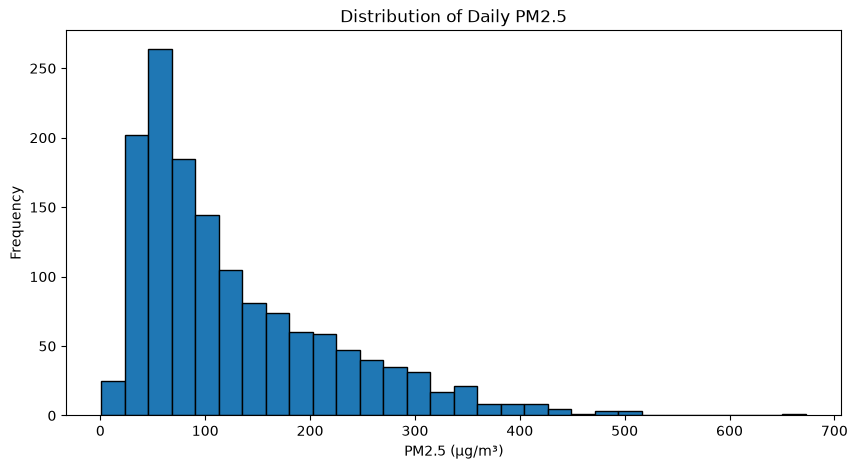

In [25]:
plt.figure(figsize=(10, 5))

plt.hist(
    combined_df["PM2.5 (µg/m³)"].dropna(),
    bins=30,
    edgecolor="black"
)

plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("Frequency")
plt.title("Distribution of Daily PM2.5")

plt.show()

In [6]:
yearly_pm25 = combined_df.groupby("Year")["PM2.5 (µg/m³)"].mean()

yearly_pm25

Year
2022    124.150164
2023    127.865413
2024    136.036948
2025    122.056556
Name: PM2.5 (µg/m³), dtype: float64

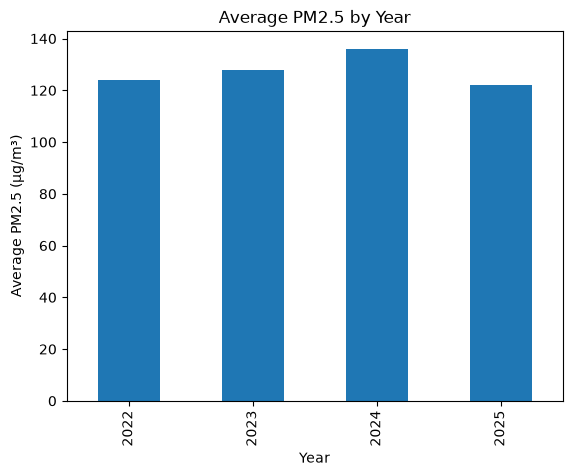

In [7]:
yearly_pm25.plot(kind="bar")

plt.ylabel("Average PM2.5 (µg/m³)")
plt.xlabel("Year")
plt.title("Average PM2.5 by Year")
plt.show()

In [8]:
monthly_pm25 = combined_df.groupby("Month")["PM2.5 (µg/m³)"].mean()

monthly_pm25

Month
1     235.887762
2     132.987497
3      95.871953
4     100.603347
5      89.786639
6      65.522717
7      42.206746
8      50.447542
9      62.701482
10    137.878338
11    263.822027
12    237.150878
Name: PM2.5 (µg/m³), dtype: float64

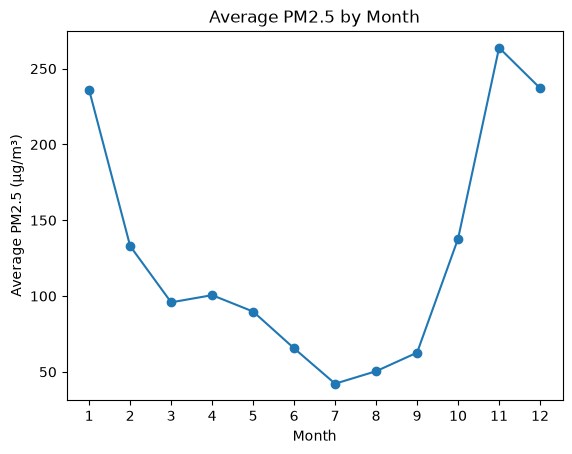

In [14]:
monthly_pm25.plot(kind="line", marker="o")

plt.xlabel("Month")
plt.ylabel("Average PM2.5 (µg/m³)")
plt.title("Average PM2.5 by Month")
plt.xticks(range(1, 13))
plt.show()

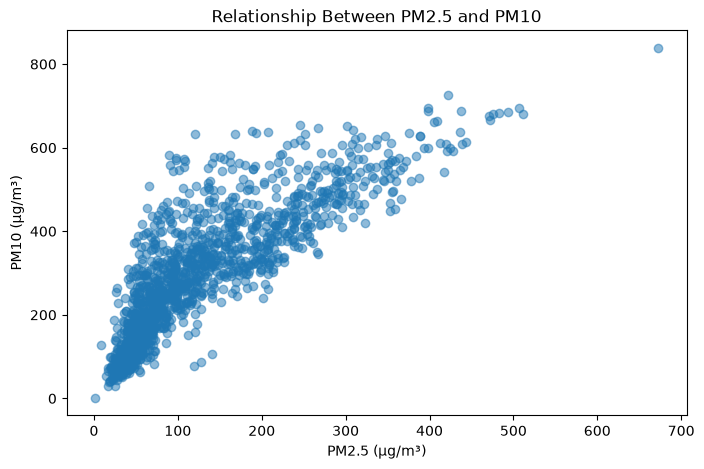

In [26]:
plt.figure(figsize=(8, 5))

plt.scatter(
    combined_df["PM2.5 (µg/m³)"],
    combined_df["PM10 (µg/m³)"],
    alpha=0.5
)

plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("PM10 (µg/m³)")
plt.title("Relationship Between PM2.5 and PM10")

plt.show()

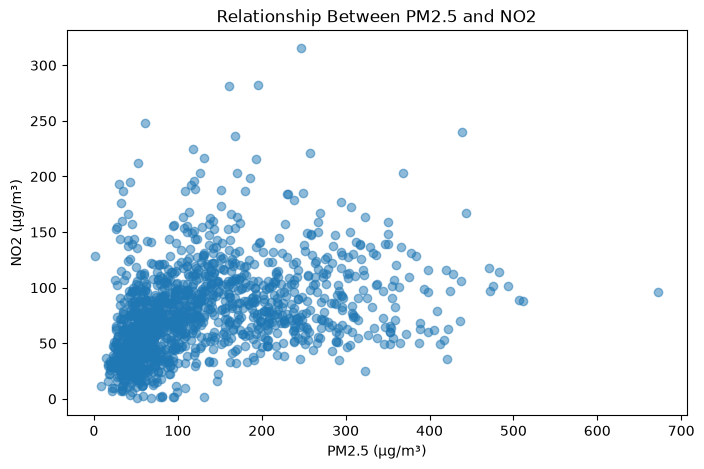

In [29]:
plt.figure(figsize=(8, 5))

plt.scatter(
    combined_df["PM2.5 (µg/m³)"],
    combined_df["NO2 (µg/m³)"],
    alpha=0.5
)

plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("NO2 (µg/m³)")
plt.title("Relationship Between PM2.5 and NO2")

plt.show()

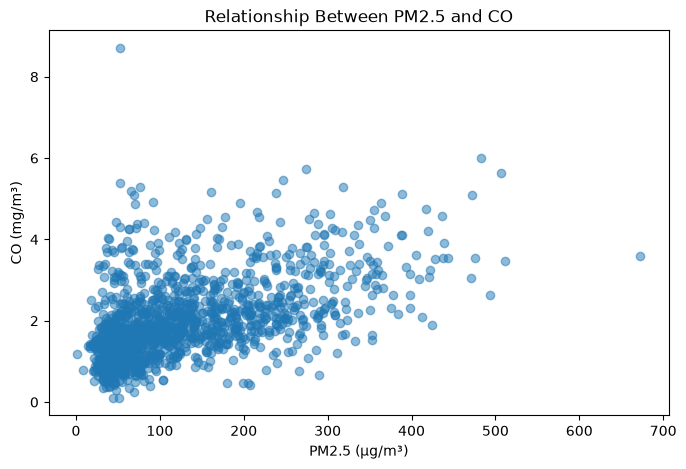

In [31]:
plt.figure(figsize=(8, 5))

plt.scatter(
    combined_df["PM2.5 (µg/m³)"],
    combined_df["CO (mg/m³)"],
    alpha=0.5
)

plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("CO (mg/m³)")
plt.title("Relationship Between PM2.5 and CO")

plt.show()

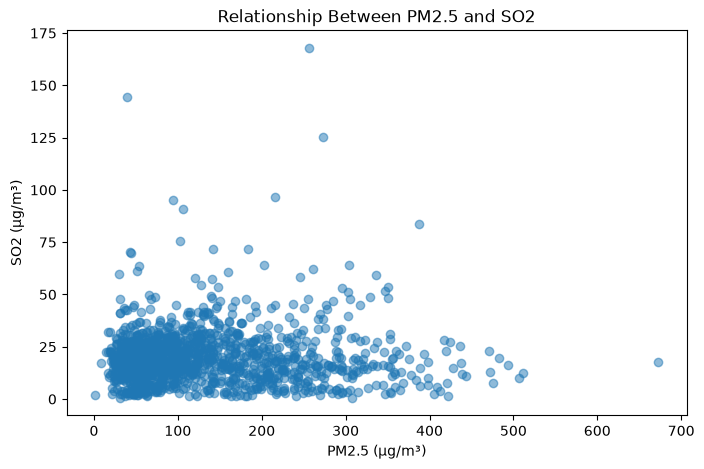

In [32]:
plt.figure(figsize=(8, 5))

plt.scatter(
    combined_df["PM2.5 (µg/m³)"],
    combined_df["SO2 (µg/m³)"],
    alpha=0.5
)

plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("SO2 (µg/m³)")
plt.title("Relationship Between PM2.5 and SO2")

plt.show()

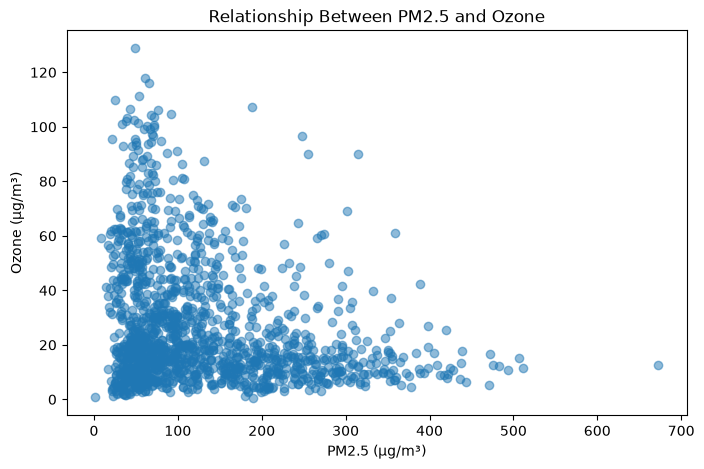

In [33]:
plt.figure(figsize=(8, 5))

plt.scatter(
    combined_df["PM2.5 (µg/m³)"],
    combined_df["Ozone (µg/m³)"],
    alpha=0.5
)

plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("Ozone (µg/m³)")
plt.title("Relationship Between PM2.5 and Ozone")

plt.show()

In [17]:
combined_df[["PM2.5 (µg/m³)", "PM10 (µg/m³)"]].corr()

,PM2.5 (µg/m³),PM10 (µg/m³)
PM2.5 (µg/m³),1.00000,0.83621
PM10 (µg/m³),0.83621,1.00000


In [43]:
variables = [
    "PM2.5 (µg/m³)",
    "PM10 (µg/m³)",
    "NO2 (µg/m³)",
    "SO2 (µg/m³)",
    "CO (mg/m³)",
    "Ozone (µg/m³)",
    "AT (°C)",
    "RH (%)",
    "WS (m/s)"
]

correlation_matrix = combined_df[variables].corr()

correlation_matrix

correlation_matrix["PM2.5 (µg/m³)"].sort_values(
    ascending=False
)

PM2.5 (µg/m³)    1.000000
PM10 (µg/m³)     0.836210
CO (mg/m³)       0.503298
NO2 (µg/m³)      0.366554
RH (%)           0.160764
SO2 (µg/m³)      0.012915
WS (m/s)        -0.151815
Ozone (µg/m³)   -0.244661
AT (°C)         -0.568700
Name: PM2.5 (µg/m³), dtype: float64

In [44]:
plt.savefig(
    "../charts/pm25_yearly_average.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 640x480 with 0 Axes>

In [45]:
year_month_pm25 = combined_df.pivot_table(
    values="PM2.5 (µg/m³)",
    index="Month",
    columns="Year",
    aggfunc="mean"
)

year_month_pm25

Year,2022,2023,2024,2025
Month,,,,
1,229.942258,225.809434,253.069032,234.730323
2,151.591786,137.856151,120.123103,122.057692
3,111.521290,99.132728,89.609091,81.406452
4,136.941000,91.249497,88.042400,84.087000
5,88.261290,81.954942,117.880000,71.050323
6,80.054000,57.024171,75.454615,50.882333
7,42.423226,36.885041,50.032258,38.456452
8,41.372258,67.199445,43.618387,51.761613
9,52.805000,53.861731,88.652308,58.947000


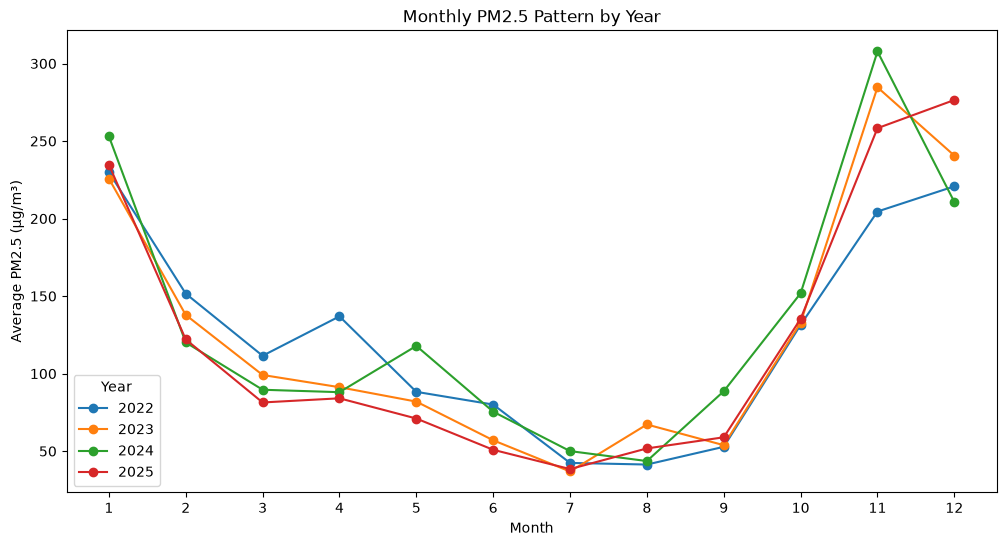

In [49]:
year_month_pm25.plot(
    kind="line",
    marker="o",
    figsize=(12, 6)
)

plt.xlabel("Month")
plt.ylabel("Average PM2.5 (µg/m³)")
plt.title("Monthly PM2.5 Pattern by Year")
plt.xticks(range(1, 13))
plt.legend(title="Year")
plt.show()

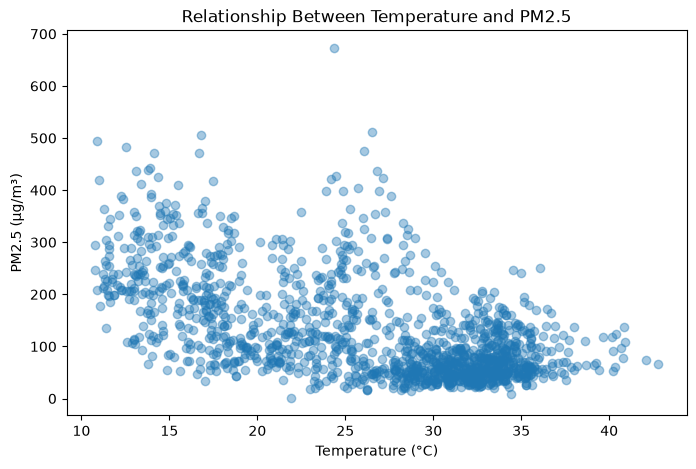

In [51]:
plt.figure(figsize=(8,5))

plt.scatter(
    cleaned_df["AT (°C)"],
    cleaned_df["PM2.5 (µg/m³)"],
    alpha=0.4
)

plt.xlabel("Temperature (°C)")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("Relationship Between Temperature and PM2.5")

plt.show()

#  hypothesis test

In [54]:
from scipy.stats import ttest_ind

pm25_2022 = cleaned_df[
    cleaned_df["Year"] == 2022
]["PM2.5 (µg/m³)"].dropna()

pm25_2025 = cleaned_df[
    cleaned_df["Year"] == 2025
]["PM2.5 (µg/m³)"].dropna()

print("2022 Mean:", pm25_2022.mean())
print("2025 Mean:", pm25_2025.mean())

t_stat, p_value = ttest_ind(
    pm25_2022,
    pm25_2025,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

2022 Mean: 124.15016438356163
2025 Mean: 122.0565564738292
T-statistic: 0.3074542707446656
P-value: 0.7585885634193157


In [55]:
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
    print("There is evidence of a difference in mean PM2.5 between 2022 and 2025.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is insufficient evidence of a difference in mean PM2.5 between 2022 and 2025.")

Fail to reject the null hypothesis.
There is insufficient evidence of a difference in mean PM2.5 between 2022 and 2025.


In [56]:
cleaned_df.to_csv(
    "../data/cleaned/air_quality_cleaned_2022_2025.csv",
    index=False
)